# R2b — Entrenar el LoRA (QLoRA) del supervisor y compararlo contra la línea base

**Línea base (R2a, 3 nov, 38 ventanas reales del split `test`):** recall 97 %, **falsas alarmas 100 %** (8/8), precision 78 % (= proporción de positivas), tipo 21 % (siempre `en_t`, azar ≈ 20 %). El modelo base dice "choque" a todo.

**Qué hace este notebook:**

1. **Datos de entrenamiento** de ACCIDENT, sin tocar `test`:
   - Videos **reales** del split `train`, de los que se aparta el 10 % de los videos como validación.
   - Videos **sintéticos** (CARLA), para tener más ejemplos de cada tipo de choque.
   - De cada video se cortan ventanas **positivas y negativas**, con las mismas reglas que R2a. Se balancea 1:1.
2. **Respuesta correcta** de cada ventana: el JSON que queremos que el modelo aprenda a escribir.
3. **QLoRA en la T4:** el modelo se carga en 4 bits (congelado) y solo se entrenan matrices pequeñas (LoRA) en la parte de lenguaje. La parte de visión no se toca.
4. **Evaluación** con las ventanas `test` de R2a, más videos `test` extra para tener al menos 30 negativas. Se evalúa **el mismo modelo en 4 bits con y sin LoRA**, así la única diferencia es el LoRA.

**Analogía:** el modelo base es un operador nuevo que sabe ver, pero nadie le explicó el formato del reporte ni le enseñó cientos de videos de "esto sí es un choque, esto no". El LoRA es esa capacitación: no le cambias los ojos (visión congelada), le enseñas el criterio (unas cuantas matrices de lenguaje).

**Tiempo estimado en T4:** descargas ~5 min · frames ~10 min · entrenamiento ~45 min (800 ejemplos) · evaluación ~20 min. **Activa `USAR_DRIVE = True`**: se guardan checkpoints cada 100 ejemplos, y si Colab se desconecta retomas desde ahí.

## 0. Instalación

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes peft huggingface_hub opencv-python-headless pandas matplotlib "kaggle>=1.7"

In [ ]:
import os, re, json, time, glob, zipfile, random, shutil, subprocess, io, math
from concurrent.futures import ThreadPoolExecutor
import torch
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} · {p.total_memory/1e9:.1f} GB · compute {p.major}.{p.minor}")

USAR_DRIVE = True        # recomendado: checkpoints y resultados sobreviven a una desconexión

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_PERSISTENTE = "/content/drive/MyDrive/roadvision"
else:
    DIR_PERSISTENTE = "/content/datos_roadvision"
DIR_LOCAL = "/content/datos_roadvision"                   # videos y frames: disco local (rápido)
DIR_ACC = os.path.join(DIR_LOCAL, "accident")
DIR_MUESTRAS = DIR_ACC
DIR_CLIPS = os.path.join(DIR_LOCAL, "clips_eval")          # frames para evaluar (generación)
DIR_CLIPS_TRAIN = os.path.join(DIR_LOCAL, "clips_train")   # frames para entrenar
DIR_RESULTADOS = os.path.join(DIR_PERSISTENTE, "resultados_qwen")
DIR_LORA = os.path.join(DIR_PERSISTENTE, "lora_supervisor")
for d in (DIR_ACC, DIR_CLIPS, DIR_CLIPS_TRAIN, DIR_RESULTADOS, DIR_LORA):
    os.makedirs(d, exist_ok=True)
EXT_VIDEO = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
SEMILLA = 0
rng = random.Random(SEMILLA)
print("Persistente:", DIR_PERSISTENTE)

GPU: Tesla T4 · 15.6 GB · compute 7.5
Mounted at /content/drive
Persistente: /content/drive/MyDrive/roadvision


## 1. Kaggle: tablas de ACCIDENT

Ya sabemos la estructura (R2a): `metadata-real.csv` y `metadata-synthetic.csv`. Aquí solo se bajan esas dos tablas; los videos van en la sección 3.

In [ ]:
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
DATASET = "picekl/accident"


def kaggle(*args, timeout=300):
    try:
        r = subprocess.run(["kaggle", *args], capture_output=True, text=True, timeout=timeout,
                           stdin=subprocess.DEVNULL)
    except subprocess.TimeoutExpired:
        raise RuntimeError(f"kaggle {' '.join(args[:3])} tardó más de {timeout} s")
    if r.returncode != 0:
        raise RuntimeError(r.stderr or r.stdout)
    return r.stdout


def bajar(nombre):
    """Baja un archivo del dataset a DIR_ACC/nombre (si no está). Devuelve (nombre, ok)."""
    destino = os.path.join(DIR_ACC, nombre)
    if os.path.exists(destino):
        return nombre, True
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    for intento in range(3):
        try:
            kaggle("datasets", "download", DATASET, "-f", nombre, "-p", os.path.dirname(destino))
            z = destino + ".zip"
            if os.path.exists(z):
                with zipfile.ZipFile(z) as zz:
                    zz.extractall(os.path.dirname(destino))
                os.remove(z)
            return nombre, os.path.exists(destino)
        except RuntimeError:
            time.sleep(2 * (intento + 1))
    return nombre, False


def bajar_varios(nombres, hilos=8):
    nombres = list(dict.fromkeys(nombres))
    t0, hechos, fallos = time.time(), 0, []
    with ThreadPoolExecutor(hilos) as ex:
        for nombre, ok in ex.map(bajar, nombres):
            hechos += 1
            if not ok:
                fallos.append(nombre)
            if hechos % 25 == 0 or hechos == len(nombres):
                print(f"  {hechos}/{len(nombres)} · {time.time()-t0:.0f} s", flush=True)
    if fallos:
        print(f"⚠️  {len(fallos)} no se pudieron bajar (se ignoran):", fallos[:5])
    return [n for n in nombres if n not in fallos]


print("Probando sesión de Kaggle...", end=" ", flush=True)
kaggle("datasets", "list", "-s", "accident", timeout=60)
print("OK")
for t in ("metadata-real.csv", "metadata-synthetic.csv"):
    bajar(t)
real = pd.read_csv(os.path.join(DIR_ACC, "metadata-real.csv"))
sint = pd.read_csv(os.path.join(DIR_ACC, "metadata-synthetic.csv"))
print("real:", real.shape, real["split_in_distribution"].value_counts().to_dict())
print("sintético:", sint.shape)

Probando sesión de Kaggle... OK
real: (2027, 22) {'test': 1520, 'train': 507}
sintético: (2211, 19)


## 2. Ventanas positivas y negativas

Mismas reglas que R2a (`VENTANA_S = 8`, `MARGEN_S = 3`, negativa de al menos 4 s). Solo da negativa un video cuyo choque ocurre a partir del segundo 7.

**Separación por video** (no por ventana): la positiva y la negativa de un video van siempre al mismo grupo. Si la negativa de un video estuviera en train y su positiva en test, el modelo ya "conocería" la escena.

In [ ]:
VENTANA_S, MARGEN_S, MIN_NEG_S = 8.0, 3.0, 4.0
T_MIN_NEG = MARGEN_S + MIN_NEG_S               # el choque debe ocurrir a partir de aquí para tener negativa

N_SINTETICOS = 300           # videos CARLA a usar
FRAC_VAL = 0.10              # fracción de videos reales de train apartados como validación
MAX_EJEMPLOS = 800           # ejemplos de entrenamiento (mitad positivas, mitad negativas)


def ventanas_de(video_id, ruta_rel, t, dur, tipo, contexto, dominio, r, n_neg=1):
    """Lista de ventanas (dicts). n_neg > 1 genera negativas con inicios distintos."""
    out = []
    antes = r.uniform(1.5, VENTANA_S - 1.5)
    ini = max(0.0, min(t - antes, dur - VENTANA_S))
    out.append({"clase": "positiva", "inicio": ini, "fin": min(dur, ini + VENTANA_S), "t_rel": t - ini})
    fin_max = t - MARGEN_S
    for _ in range(n_neg):
        if fin_max < MIN_NEG_S:
            break
        largo = min(VENTANA_S, fin_max)
        fin = r.uniform(max(largo, fin_max - 4.0), fin_max)   # varía el final para no repetir la misma ventana
        out.append({"clase": "negativa", "inicio": max(0.0, fin - largo), "fin": fin, "t_rel": None})
    for v in out:
        v.update({"video": video_id, "ruta_rel": ruta_rel, "t_choque": t, "tipo_real": tipo,
                  "contexto": contexto, "dominio": dominio})
    return out


# --- videos reales de train → train / val por video
tr = real[real["split_in_distribution"] == "train"].copy()
tr["video"] = tr["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
videos_tr = sorted(tr["video"].unique())
rng.shuffle(videos_tr)
n_val = max(5, int(len(videos_tr) * FRAC_VAL))
VIDEOS_VAL = set(videos_tr[:n_val])
tr["grupo"] = np.where(tr["video"].isin(VIDEOS_VAL), "val", "train")

# --- sintéticos estratificados por tipo
por_tipo = N_SINTETICOS // sint["type"].nunique()
si = sint.sample(frac=1, random_state=SEMILLA).groupby("type").head(por_tipo).copy()
si["video"] = si["rgb_path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
si["grupo"] = "train"


def contexto_real(f):
    return {"lugar": f.get("scene_layout"), "hora": f.get("day_time"), "clima": f.get("weather")}


def contexto_sint(f):
    return {"lugar": None, "hora": "night" if "night" in str(f.get("weather")) else "day", "clima": f.get("weather")}


candidatas = []
for _, f in tr.iterrows():
    for v in ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                         contexto_real(f), "real", rng, n_neg=2):
        v["grupo"] = f["grupo"]; candidatas.append(v)
for _, f in si.iterrows():
    for v in ventanas_de(f["video"], f["rgb_path"], f["accident_time"], f["duration"], f["type"],
                         contexto_sint(f), "sintetico", rng, n_neg=2):
        v["grupo"] = "train"; candidatas.append(v)
CAND = pd.DataFrame(candidatas)
print(CAND.groupby(["grupo", "dominio", "clase"]).size().unstack(fill_value=0))

# --- balanceo 1:1 en train
mitad = MAX_EJEMPLOS // 2
tr_c = CAND[CAND["grupo"] == "train"]
neg = tr_c[tr_c["clase"] == "negativa"]
neg = neg.sample(mitad, replace=len(neg) < mitad, random_state=SEMILLA)
pos = tr_c[tr_c["clase"] == "positiva"]
pos = pos.sample(frac=1, random_state=SEMILLA).groupby("dominio").head(mitad // 2)
pos = pd.concat([pos, tr_c[(tr_c["clase"] == "positiva") & ~tr_c.index.isin(pos.index)].sample(
    max(0, mitad - len(pos)), random_state=SEMILLA)])
TRAIN = pd.concat([pos, neg]).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
VAL = CAND[CAND["grupo"] == "val"].reset_index(drop=True)
print(f"\nTRAIN: {len(TRAIN)} ventanas · {TRAIN['clase'].value_counts().to_dict()} · "
      f"{TRAIN['dominio'].value_counts().to_dict()} · {TRAIN['video'].nunique()} videos")
print(f"VAL:   {len(VAL)} ventanas · {VAL['clase'].value_counts().to_dict()}")
print("Negativas repetidas (mismo video, distinto corte):", int(neg.duplicated(["video", "inicio"]).sum()), "copias exactas")

clase            negativa  positiva
grupo dominio                      
train real            186       457
      sintetico       270       300
val   real             14        50

TRAIN: 800 ventanas · {'positiva': 400, 'negativa': 400} · {'sintetico': 438, 'real': 362} · 495 videos
VAL:   64 ventanas · {'positiva': 50, 'negativa': 14}
Negativas repetidas (mismo video, distinto corte): 115 copias exactas


### Ventanas de prueba (test)

1. Si el CSV de R2a está en `resultados_qwen/` (en Drive) o lo subes a `/content/`, se usan **exactamente esas ventanas**.
2. Se agregan videos `test` **extra** (con choque después del segundo 7) hasta tener `MIN_NEG_TEST` negativas. Con 8 negativas, un 100 % de falsas alarmas podría ser 63–100 % en realidad; con 30 el número es más confiable.

In [ ]:
MIN_NEG_TEST = 30

csvs = sorted(glob.glob(os.path.join(DIR_RESULTADOS, "linea_base_accident_*.csv")) +
              glob.glob("/content/linea_base_accident_*.csv"))
te = real[real["split_in_distribution"] == "test"].copy()
te["video"] = te["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
filas_test = []
if csvs:
    previo = pd.read_csv(csvs[-1])
    previo = previo[previo["ruta"].str.contains("real_videos")]
    print(f"Usando ventanas de R2a: {csvs[-1]} ({len(previo)} ventanas)")
    for _, f in previo.iterrows():
        filas_test.append({"clase": f["clase"], "inicio": f["inicio"], "fin": f["fin"],
                           "t_rel": f["t_rel"] if f["clase"] == "positiva" else None,
                           "video": f["video"], "ruta_rel": "real_videos/" + os.path.basename(f["ruta"]),
                           "t_choque": f["t_choque"], "tipo_real": f["tipo_real"], "origen": "R2a"})
else:
    print("⚠️  No encontré el CSV de R2a: todas las ventanas de test serán nuevas (la comparación "
          "base vs. LoRA sigue siendo justa porque ambos se evalúan aquí).")

usados = {f["video"] for f in filas_test}
extra = te[(te["accident_time"] >= T_MIN_NEG) & ~te["video"].isin(usados)].sample(frac=1, random_state=SEMILLA)
r_test = random.Random(SEMILLA + 1)
for _, f in extra.iterrows():
    if sum(x["clase"] == "negativa" for x in filas_test) >= MIN_NEG_TEST:
        break
    for v in ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                         contexto_real(f), "real", r_test, n_neg=1):
        v["origen"] = "extra"; filas_test.append(v)
TEST = pd.DataFrame(filas_test)
assert not (set(TEST["video"]) & set(TRAIN["video"]) | set(TEST["video"]) & set(VAL["video"])), "¡Fuga test↔train!"
print(f"TEST: {len(TEST)} ventanas · {TEST['clase'].value_counts().to_dict()} · {TEST['origen'].value_counts().to_dict()}")

⚠️  No encontré el CSV de R2a: todas las ventanas de test serán nuevas (la comparación base vs. LoRA sigue siendo justa porque ambos se evalúan aquí).
TEST: 60 ventanas · {'positiva': 30, 'negativa': 30} · {'extra': 60}


## 3. Bajar el dataset completo (una sola vez) y sacar solo los videos necesarios

En la corrida anterior, 470 de 575 descargas sueltas fallaron: Kaggle corta cuando le haces cientos de peticiones seguidas. Ahora se baja **un solo ZIP de ~20 GB** (una petición, con barra de progreso) al disco local de Colab, y de ahí se **extraen solo los videos que se usan**. Es como pedir la caja completa en lugar de 575 envíos sueltos.

El ZIP no cabe en el Drive gratis (15 GB), así que vive en `/content`: si la sesión se reinicia, se vuelve a bajar (~5–10 min).

In [ ]:
libre_gb = shutil.disk_usage("/content").free / 1e9
print(f"Disco libre: {libre_gb:.0f} GB")
assert libre_gb > 30, "Hacen falta ~30 GB libres (20 del ZIP + videos extraídos + frames)"

ZIP = next(iter(glob.glob(os.path.join(DIR_LOCAL, "*.zip"))), None)
if ZIP is not None and not zipfile.is_zipfile(ZIP):
    print("ZIP incompleto de una sesión anterior: se borra y se baja de nuevo")
    os.remove(ZIP); ZIP = None
if ZIP is None:
    t0 = time.time()
    !kaggle datasets download {DATASET} -p {DIR_LOCAL}
    ZIP = glob.glob(os.path.join(DIR_LOCAL, "*.zip"))[0]
    print(f"Descargado en {(time.time()-t0)/60:.1f} min")
zf = zipfile.ZipFile(ZIP)
miembros = set(zf.namelist())
print(f"ZIP: {os.path.getsize(ZIP)/1e9:.1f} GB · {len(miembros)} archivos")

Disco libre: 120 GB
Dataset URL: https://www.kaggle.com/datasets/picekl/accident
License(s): CC-BY-NC-SA-4.0
100% 15.6G/15.6G [04:08<00:00, 67.6MB/s]

Descargado en 4.2 min
ZIP: 16.8 GB · 6452 archivos


In [ ]:
necesarios = sorted(set(TRAIN["ruta_rel"]) | set(VAL["ruta_rel"]) | set(TEST["ruta_rel"]))
faltan_zip = [n for n in necesarios if n not in miembros]
if faltan_zip:
    print(f"⚠️  {len(faltan_zip)} rutas no están en el ZIP, ej.: {faltan_zip[:3]}")
t0 = time.time()
for k, n in enumerate(necesarios, 1):
    if n in miembros and not os.path.exists(os.path.join(DIR_ACC, n)):
        zf.extract(n, DIR_ACC)
    if k % 100 == 0:
        print(f"  {k}/{len(necesarios)} · {time.time()-t0:.0f} s", flush=True)
ok = {n for n in necesarios if os.path.exists(os.path.join(DIR_ACC, n))}
print(f"{len(ok)}/{len(necesarios)} videos listos · {time.time()-t0:.0f} s")
for nombre, df in (("TRAIN", TRAIN), ("VAL", VAL), ("TEST", TEST)):
    antes = len(df)
    df.drop(df[~df["ruta_rel"].isin(ok)].index, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"{nombre}: {len(df)}/{antes} ventanas con video")
assert len(TRAIN) > 0.9 * MAX_EJEMPLOS, "Faltan demasiados videos: no entrenes así, revisa el aviso de arriba"
for df in (TRAIN, VAL, TEST):
    df["ruta"] = df["ruta_rel"].map(lambda n: os.path.join(DIR_ACC, n))

  100/575 · 1 s
  200/575 · 4 s
  300/575 · 5 s
  400/575 · 15 s
  500/575 · 21 s
575/575 videos listos · 24 s
TRAIN: 800/800 ventanas con video
VAL: 64/64 ventanas con video
TEST: 60/60 ventanas con video


## 4. Frames y respuesta correcta de cada ventana

Los frames se extraen **una sola vez** (16 por ventana, misma resolución que R2a). Durante el entrenamiento solo se leen del disco.

La respuesta correcta es el JSON del supervisor. ACCIDENT no trae descripciones escritas por humanos, así que `descripcion` se arma con una plantilla a partir de los metadatos (tipo, lugar, hora). En el reporte hay que decir que la descripción es de plantilla: lo valioso que aprende el modelo es `incidente`, `tipo` y `segundo_aprox`.

In [ ]:
def info_video(ruta_video):
    cap = cv2.VideoCapture(ruta_video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return fps, total, (total / fps if fps > 0 else 0), ancho, alto


FPS_VIDEO = 2.0
MAX_FRAMES = 16
MAX_PIXELES_VIDEO = 360 * 420

TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}
MAPEO_TIPO = {   # clase de ACCIDENT (inglés) → clase del JSON
    "head-on": "frontal", "head_on": "frontal", "headon": "frontal",
    "rear-end": "alcance", "rear_end": "alcance", "rearend": "alcance",
    "t-bone": "en_t", "t_bone": "en_t", "tbone": "en_t",
    "sideswipe": "roce_lateral", "side-swipe": "roce_lateral",
    "single": "un_vehiculo", "single-vehicle": "un_vehiculo", "single_vehicle": "un_vehiculo",
}


def tipo_json(valor):
    v = str(valor).strip().lower()
    return MAPEO_TIPO.get(v, MAPEO_TIPO.get(v.replace(" ", "-"), "otro"))


def muestrear_ventana(ruta, inicio, fin, max_frames=MAX_FRAMES, carpeta_id=""):
    fps, total, dur, ancho, alto = info_video(ruta)
    largo = fin - inicio
    n = int(min(max_frames, max(2, largo * FPS_VIDEO)))
    n -= n % 2
    tiempos = [inicio + i * largo / n for i in range(n)]
    escala = min(1.0, (MAX_PIXELES_VIDEO / (ancho * alto)) ** 0.5)
    tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))
    carpeta = os.path.join(DIR_CLIPS, carpeta_id)
    shutil.rmtree(carpeta, ignore_errors=True); os.makedirs(carpeta, exist_ok=True)
    cap = cv2.VideoCapture(ruta)
    rutas = []
    for k, t in enumerate(tiempos):
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        ok, img = cap.read()
        if ok:
            r = os.path.join(carpeta, f"{k:03d}.jpg")
            cv2.imwrite(r, cv2.resize(img, tam, interpolation=cv2.INTER_AREA))
            rutas.append(r)
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    return rutas, (len(rutas) / largo if largo > 0 else FPS_VIDEO), largo



NOMBRE_TIPO = {"frontal": "frontal", "alcance": "por alcance", "en_t": "en T",
               "roce_lateral": "por roce lateral", "un_vehiculo": "de un solo vehículo"}
LUGAR = {"highway": "una autopista", "signalized_intersection": "un cruce con semáforo",
         "unsignalized_intersection": "un cruce sin semáforo", "roundabout": "una glorieta",
         "urban_road": "una calle urbana", "rural_road": "un camino rural"}


def respuesta_correcta(v):
    ctx = v["contexto"] if isinstance(v.get("contexto"), dict) else {}
    lugar = LUGAR.get(str(ctx.get("lugar")), "la vía")
    hora = " de noche" if str(ctx.get("hora")).lower() == "night" else ""
    if v["clase"] == "positiva":
        t = tipo_json(v["tipo_real"])
        r = {"incidente": True, "tipo": t, "segundo_aprox": round(float(v["t_rel"]), 1), "camara_fija": True,
             "descripcion": f"Choque {NOMBRE_TIPO.get(t, '')} en {lugar}{hora}.".replace("  ", " ")}
    else:
        r = {"incidente": False, "tipo": "ninguno", "segundo_aprox": None, "camara_fija": True,
             "descripcion": f"Tráfico normal en {lugar}{hora}, sin choques."}
    return json.dumps(r, ensure_ascii=False)


def preparar_frames(df, carpeta_base, prefijo):
    rutas, fpss, durs = [], [], []
    t0 = time.time()
    for i, v in df.iterrows():
        carpeta = f"{prefijo}{i:05d}"
        hecho = os.path.join(carpeta_base, carpeta, "_ok.json")
        if os.path.exists(hecho):
            info = json.load(open(hecho))
        else:
            # una ruta absoluta en carpeta_id hace que os.path.join ignore DIR_CLIPS
            r, fps_ef, largo = muestrear_ventana(v["ruta"], v["inicio"], v["fin"], MAX_FRAMES,
                                                 os.path.join(carpeta_base, carpeta))
            info = {"frames": r, "fps": fps_ef, "dur": largo}
            json.dump(info, open(hecho, "w"))
        rutas.append(info["frames"]); fpss.append(info["fps"]); durs.append(info["dur"])
        if (i + 1) % 100 == 0:
            print(f"  {prefijo}: {i+1}/{len(df)} · {time.time()-t0:.0f} s", flush=True)
    df["frames"], df["fps_ef"], df["dur"] = rutas, fpss, durs
    df.drop(df[df["frames"].map(len) < 2].index, inplace=True)
    df.reset_index(drop=True, inplace=True)


def muestrear_ventana(ruta, inicio, fin, max_frames=MAX_FRAMES, carpeta_id=""):
    """Como en R2a, pero leyendo el video EN ORDEN desde el inicio de la ventana.
    Buscar cada frame (cap.set) obliga a decodificar desde el keyframe anterior 16 veces;
    leer de corrido decodifica cada frame una sola vez. En la corrida anterior tardaba ~2.6 s por ventana."""
    fps, total, dur, ancho, alto = info_video(ruta)
    largo = fin - inicio
    n = int(min(max_frames, max(2, largo * FPS_VIDEO)))
    n -= n % 2
    tiempos = [inicio + i * largo / n for i in range(n)]
    escala = min(1.0, (MAX_PIXELES_VIDEO / (ancho * alto)) ** 0.5) if ancho * alto else 1.0
    tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))
    carpeta = os.path.join(DIR_CLIPS, carpeta_id)
    shutil.rmtree(carpeta, ignore_errors=True); os.makedirs(carpeta, exist_ok=True)
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, inicio - 0.5) * 1000)
    rutas, k = [], 0
    while k < len(tiempos) and cap.grab():
        t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
        if t + 1e-3 >= tiempos[k]:
            ok, img = cap.retrieve()
            if ok:
                r = os.path.join(carpeta, f"{len(rutas):03d}.jpg")
                cv2.imwrite(r, cv2.resize(img, tam, interpolation=cv2.INTER_AREA))
                rutas.append(r)
            k += 1
            while k < len(tiempos) and t + 1e-3 >= tiempos[k]:   # video de pocos fps: saltar metas ya pasadas
                k += 1
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    return rutas, (len(rutas) / largo if largo > 0 else FPS_VIDEO), largo


preparar_frames(TRAIN, DIR_CLIPS_TRAIN, "tr")
preparar_frames(VAL, DIR_CLIPS_TRAIN, "va")
TRAIN["respuesta"] = TRAIN.apply(respuesta_correcta, axis=1)
VAL["respuesta"] = VAL.apply(respuesta_correcta, axis=1)
print("Ejemplos de respuesta correcta:")
for c in ("positiva", "negativa"):
    print(" ", c, "→", TRAIN[TRAIN["clase"] == c]["respuesta"].iloc[0])

  tr: 100/800 · 98 s
  tr: 200/800 · 210 s
  tr: 300/800 · 313 s
  tr: 400/800 · 429 s
  tr: 500/800 · 525 s
  tr: 600/800 · 623 s
  tr: 700/800 · 721 s
  tr: 800/800 · 818 s
Ejemplos de respuesta correcta:
  positiva → {"incidente": true, "tipo": "alcance", "segundo_aprox": 1.0, "camara_fija": true, "descripcion": "Choque por alcance en una autopista de noche."}
  negativa → {"incidente": false, "tipo": "ninguno", "segundo_aprox": null, "camara_fija": true, "descripcion": "Tráfico normal en la vía, sin choques."}


## 5. Cargar Qwen2.5-VL-3B en 4 bits + LoRA

- **4 bits (NF4):** los pesos originales se guardan comprimidos y **congelados**. Así el modelo de 3B cabe con espacio para entrenar.
- **LoRA:** a cada capa lineal de la parte de **lenguaje** se le suma `B·A`, dos matrices delgadas (rango `r = 16`). Solo esas se entrenan: son ~1 % de los parámetros.
- La expresión regular `OBJETIVOS` excluye todo lo que tenga `visual` en el nombre: la visión queda intacta.
- `gradient checkpointing`: en lugar de guardar todas las activaciones para el *backward*, se recalculan. Más lento, pero cabe en 15 GB.

In [ ]:
import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from qwen_vl_utils import process_vision_info

MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MIN_PIX, MAX_PIX = 256 * 28 * 28, 1024 * 28 * 28
print("transformers", transformers.__version__)

cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float16)
t0 = time.time()
modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODELO_ID, quantization_config=cuant, device_map={"": 0}, attn_implementation="sdpa")
try:
    procesador = AutoProcessor.from_pretrained(MODELO_ID, size={"shortest_edge": MIN_PIX, "longest_edge": MAX_PIX})
except (TypeError, ValueError):
    procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=MIN_PIX, max_pixels=MAX_PIX)

modelo = prepare_model_for_kbit_training(modelo, use_gradient_checkpointing=True,
                                         gradient_checkpointing_kwargs={"use_reentrant": False})
OBJETIVOS = r"^(?!.*visual).*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$"
config_lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                         target_modules=OBJETIVOS, task_type="CAUSAL_LM")

# Huella de los datos de entrenamiento: si cambian (otra semilla, otro MAX_EJEMPLOS), es otro experimento
# y NO se retoma un checkpoint viejo. En la corrida anterior se retomó uno de otros datos por error.
import hashlib
config_exp = {"datos": TRAIN[["video", "clase", "inicio"]].round(3).astype(str).values.tolist(),
              "lr": 2e-4, "r": 16, "acum": 8}
HUELLA = hashlib.md5(json.dumps(config_exp).encode()).hexdigest()[:8]
DIR_EXP = os.path.join(DIR_LORA, f"exp_{HUELLA}")
os.makedirs(DIR_EXP, exist_ok=True)
print("Experimento:", DIR_EXP)
ultimo = sorted(glob.glob(os.path.join(DIR_EXP, "paso_*")), key=lambda p: int(p.split("_")[-1]))
if ultimo:
    modelo = PeftModel.from_pretrained(modelo, ultimo[-1], is_trainable=True)
    INICIO = int(json.load(open(os.path.join(ultimo[-1], "estado.json")))["ejemplo"])
    print(f"Retomando desde {ultimo[-1]} (ejemplo {INICIO})")
else:
    modelo = get_peft_model(modelo, config_lora)
    INICIO = 0
modelo.print_trainable_parameters()
en_visual = sum(p.numel() for n, p in modelo.named_parameters() if p.requires_grad and "visual" in n)
assert en_visual == 0, "El LoRA se metió en la parte visual"
print(f"Cargado en {time.time()-t0:.0f} s · VRAM {torch.cuda.memory_allocated()/1e9:.1f} GB")

transformers 5.22.0


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Experimento: /content/drive/MyDrive/roadvision/lora_supervisor/exp_4dd8dd4a
Retomando desde /content/drive/MyDrive/roadvision/lora_supervisor/exp_4dd8dd4a/paso_500 (ejemplo 500)
trainable params: 29,933,568 || all params: 3,784,556,544 || trainable%: 0.7909
Cargado en 121 s · VRAM 3.2 GB


### Funciones de R1.2/R2a (preguntar, parser, prompt)

Mismo prompt que R2a, para que la comparación sea justa.

In [ ]:
from qwen_vl_utils import process_vision_info

_CAP_OK = True   # se apaga solo si esta versión de transformers no reconoce cap_pixels_per_frame


def preguntar(contenido, max_new_tokens=256, fps_video=None):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    global _CAP_OK
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps_video is not None:          # cuando mandamos frames sueltos, el fps real lo sabemos nosotros
            fps = fps_video
        if fps is not None:
            extra["fps"] = float(fps)
        if _CAP_OK:
            extra["cap_pixels_per_frame"] = True

    try:
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    except TypeError:
        _CAP_OK = False
        extra.pop("cap_pixels_per_frame", None)
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    entradas = entradas.to(modelo.device)

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def _primer_json(t):
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None


def _reparar_lineas(t):
    """Pone comillas a valores que no son JSON válido: "clave": 2011-07-04 09:51:13,  ->  "clave": "2011-07-04 09:51:13","""
    salida = []
    for linea in t.splitlines():
        m = re.match(r'^(\s*"[^"]+"\s*:\s*)(.+?)(\s*,?\s*)$', linea)
        if m:
            valor = m.group(2)
            try:
                json.loads(valor)
            except json.JSONDecodeError:
                valor = json.dumps(valor.strip().strip('"'), ensure_ascii=False)
            linea = m.group(1) + valor + m.group(3)
        salida.append(linea)
    return "\n".join(salida)


def extraer_json(texto):
    """Devuelve (objeto_o_None, reparado: bool)."""
    t = re.sub(r"```(?:json)?", "", texto)
    obj = _primer_json(t)
    if obj is not None:
        return obj, False
    obj = _primer_json(_reparar_lineas(t))
    return obj, obj is not None


TIPOS = {"choque_vehiculos", "atropello", "moto_caida", "vehiculo_detenido", "otro", "ninguno"}
FRASES_PLANTILLA = {"una oración en español", "una oracion en español", ""}


def _a_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str) and x.strip().lower() in ("true", "false", "sí", "si", "no"):
        return x.strip().lower() in ("true", "sí", "si")
    return None


def normalizar_juicio(datos, duracion_s):
    """Valida campos y anota qué estaba mal. Devuelve un dict limpio."""
    problemas = []
    inc = _a_bool(datos.get("incidente"))
    if inc is None:
        problemas.append("incidente")
    tipo = str(datos.get("tipo", "")).strip().lower()
    if tipo not in TIPOS:
        problemas.append("tipo"); tipo = "otro" if inc else "ninguno"
    seg = datos.get("segundo_aprox")
    if not isinstance(seg, (int, float)) or isinstance(seg, bool) or not (0 <= seg <= duracion_s + 1):
        if seg is not None:
            problemas.append("segundo_aprox")
        seg = None
    fija = _a_bool(datos.get("camara_fija"))
    desc = str(datos.get("descripcion", "")).strip()
    if desc.lower() in FRASES_PLANTILLA:
        problemas.append("descripcion")
    return {"incidente": inc, "tipo": tipo, "segundo_aprox": seg, "camara_fija": fija,
            "descripcion": desc, "campos_malos": ",".join(problemas)}


# Prueba rápida del parser con la respuesta real que falló el 22 de octubre
_ejemplo = '```json\n{\n  "incidente": true,\n  "tipo": "atropello",\n  "segundo_aprox": 2011-07-04 09:51:13,\n  "camara_fija": false,\n  "descripcion": "una oración en español"\n}\n```'
_obj, _rep = extraer_json(_ejemplo)
print("reparado:", _rep, "→", normalizar_juicio(_obj, duracion_s=12))

reparado: True → {'incidente': True, 'tipo': 'atropello', 'segundo_aprox': None, 'camara_fija': False, 'descripcion': 'una oración en español', 'campos_malos': 'segundo_aprox,descripcion'}


In [ ]:
PROMPT_INCIDENTE = (
    "Eres operador de un centro de monitoreo de tráfico (C5). Mira el video de una cámara de vigilancia "
    "y decide si ocurre un choque.\n"
    "El video dura {dur:.0f} segundos.\n"
    "Responde SOLO con un objeto JSON con estas claves:\n"
    "- incidente: true o false\n"
    "- tipo: una de frontal, alcance, en_t, roce_lateral, un_vehiculo, otro, ninguno "
    "(alcance = un vehículo pega por detrás a otro; en_t = un vehículo pega en el costado de otro en un cruce; "
    "roce_lateral = dos vehículos se rozan de lado; un_vehiculo = choca solo contra un objeto; "
    "ninguno si incidente es false)\n"
    "- segundo_aprox: segundo en que ocurre el choque, un número entre 0 y {dur:.0f}; null si no hay choque\n"
    "- camara_fija: true si la cámara está quieta (poste o vigilancia), false si va dentro de un vehículo\n"
    "- descripcion: una oración en español que diga lo que se ve\n"
    "Ignora fechas, horas, velocidades y logotipos sobreimpresos en la imagen.\n"
    "Ejemplo de formato con valores inventados:\n"
    '{{"incidente": false, "tipo": "ninguno", "segundo_aprox": null, "camara_fija": true, '
    '"descripcion": "Tráfico fluido en una avenida de dos carriles sin eventos."}}'
)



# El bloque de funciones de apoyo redefine TIPOS con las clases viejas: se restauran las de ACCIDENT
TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}


def juzgar_ventana(v, idx):
    rutas, fps_ef, dur = muestrear_ventana(v["ruta"], v["inicio"], v["fin"], MAX_FRAMES, f"e{idx:04d}")
    if len(rutas) < 2:
        return {"incidente": None, "tipo": "video_ilegible", "formato": "sin_video"}
    with torch.autocast("cuda", dtype=torch.float16):
        resp, seg, entradas = preguntar([
            {"type": "video", "video": [f"file://{r}" for r in rutas]},
            {"type": "text", "text": PROMPT_INCIDENTE.format(dur=dur)},
        ], max_new_tokens=200, fps_video=fps_ef)
    datos, reparado = extraer_json(resp)
    if isinstance(datos, dict):
        r = normalizar_juicio(datos, dur)
        r["formato"] = "reparado" if reparado else "ok"
    else:
        r = {"incidente": None, "tipo": "sin_json", "formato": "irrecuperable"}
    r.update({"segundos": round(seg, 2), "respuesta_cruda": resp})
    return r

## 6. Convertir una ventana en tensores con etiquetas

El modelo ve la conversación completa (video + pregunta + respuesta correcta), pero la **pérdida solo se calcula sobre la respuesta**. Los tokens del video y de la pregunta llevan etiqueta `-100`, que significa "no califiques esto". Es como un examen donde solo se califica lo que el alumno escribe, no el enunciado.

In [ ]:
MARCA_ASISTENTE = procesador.tokenizer.encode("<|im_start|>assistant\n", add_special_tokens=False)


def inicio_respuesta(ids, marca=MARCA_ASISTENTE):
    """Posición del primer token después de la última aparición de la marca del asistente."""
    n = len(marca)
    for i in range(len(ids) - n, -1, -1):
        if ids[i:i + n] == marca:
            return i + n
    raise ValueError("No encontré la marca del asistente")


def tensores(v):
    usuario = {"role": "user", "content": [
        {"type": "video", "video": [f"file://{r}" for r in v["frames"]]},
        {"type": "text", "text": PROMPT_INCIDENTE.format(dur=v["dur"])}]}
    asistente = {"role": "assistant", "content": [{"type": "text", "text": v["respuesta"]}]}
    texto = procesador.apply_chat_template([usuario, asistente], tokenize=False, add_generation_prompt=False)
    _, vids, _ = process_vision_info([usuario], return_video_kwargs=True)
    extra = {"fps": float(v["fps_ef"])}
    if _CAP_OK:
        extra["cap_pixels_per_frame"] = True
    try:
        ent = procesador(text=[texto], videos=vids, return_tensors="pt", **extra)
    except TypeError:
        extra.pop("cap_pixels_per_frame", None)
        ent = procesador(text=[texto], videos=vids, return_tensors="pt", **extra)
    ids = ent["input_ids"][0].tolist()
    k = inicio_respuesta(ids)
    etiquetas = torch.full_like(ent["input_ids"], -100)
    etiquetas[0, k:] = ent["input_ids"][0, k:]
    ent["labels"] = etiquetas
    return ent.to(modelo.device)


ej = tensores(TRAIN.iloc[0])
k = int((ej["labels"][0] != -100).nonzero()[0])
print(f"Tokens totales: {ej['input_ids'].shape[1]} · calificados: {int((ej['labels'] != -100).sum())}")
print("Lo que se califica:", repr(procesador.tokenizer.decode(ej["input_ids"][0, k:])))
del ej

Tokens totales: 1922 · calificados: 51
Lo que se califica: '{"incidente": true, "tipo": "alcance", "segundo_aprox": 1.0, "camara_fija": true, "descripcion": "Choque por alcance en una autopista de noche."}<|im_end|>\n'


## 7. Entrenamiento

- **Lote efectivo de 8** (`ACUM = 8`): se procesa 1 ventana a la vez (no caben más), y cada 8 se actualizan los pesos.
- **Tasa de aprendizaje** `2e-4` con calentamiento corto y bajada lineal: lo estándar en QLoRA.
- **Precisión mixta fp16** con `GradScaler`: la T4 no tiene bf16. Si una ventana da pérdida `nan`/`inf`, se salta y se cuenta.
- Cada 100 ejemplos: pérdida de **validación** (30 ventanas de videos que no se entrenan) y **checkpoint** en Drive.

In [ ]:
LR, ACUM, EPOCAS, CALENTAMIENTO = 2e-4, 8, 1, 10
CADA_GUARDAR, N_VAL_LOSS = 100, 30

parametros = [p for p in modelo.parameters() if p.requires_grad]
opt = torch.optim.AdamW(parametros, lr=LR, weight_decay=0.0)
total_pasos = math.ceil(len(TRAIN) * EPOCAS / ACUM)
sched = transformers.get_linear_schedule_with_warmup(opt, CALENTAMIENTO, total_pasos)
escalador = torch.amp.GradScaler("cuda")
for _ in range(INICIO // ACUM):
    sched.step()
estado_previo = os.path.join(ultimo[-1], "optimizador.pt") if ultimo else None
if estado_previo and os.path.exists(estado_previo):
    opt.load_state_dict(torch.load(estado_previo))

val_idx = VAL.sample(min(N_VAL_LOSS, len(VAL)), random_state=SEMILLA).index


def perdida_val():
    modelo.eval()
    vals = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for i in val_idx:
            l = modelo(**tensores(VAL.loc[i])).loss
            if torch.isfinite(l):
                vals.append(l.item())
    modelo.train()
    return float(np.mean(vals)) if vals else float("nan")


def guardar(n_ejemplo):
    carpeta = os.path.join(DIR_EXP, f"paso_{n_ejemplo}")
    modelo.save_pretrained(carpeta)
    torch.save(opt.state_dict(), os.path.join(carpeta, "optimizador.pt"))
    json.dump({"ejemplo": n_ejemplo, "historial": historial}, open(os.path.join(carpeta, "estado.json"), "w"))
    for viejo in sorted(glob.glob(os.path.join(DIR_EXP, "paso_*")), key=lambda p: int(p.split("_")[-1]))[:-2]:
        shutil.rmtree(viejo, ignore_errors=True)          # solo se guardan los 2 últimos


historial = json.load(open(os.path.join(ultimo[-1], "estado.json")))["historial"] if ultimo else []
orden = list(range(len(TRAIN))) * EPOCAS
assert INICIO < len(orden) or os.path.exists(os.path.join(DIR_EXP, "final")), "Checkpoint inconsistente"
modelo.config.use_cache = False
modelo.train()
t0, saltados, acumulado = time.time(), 0, []
if INICIO == 0:
    historial.append({"ejemplo": 0, "val": perdida_val()})
    print(f"Pérdida de validación inicial: {historial[-1]['val']:.3f}")

for n, i in enumerate(orden[INICIO:], start=INICIO + 1):
    try:
        with torch.autocast("cuda", dtype=torch.float16):
            perdida = modelo(**tensores(TRAIN.iloc[i])).loss
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); saltados += 1; continue
    if not torch.isfinite(perdida):
        saltados += 1
    else:
        escalador.scale(perdida / ACUM).backward()
        acumulado.append(perdida.item())
    if n % ACUM == 0 and any(q.grad is not None for q in parametros):
        escalador.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(parametros, 1.0)
        escalador.step(opt); escalador.update(); opt.zero_grad(set_to_none=True); sched.step()
    if n % 20 == 0:
        media = float(np.mean(acumulado[-20:])) if acumulado else float("nan")
        historial.append({"ejemplo": n, "train": media})
        restante = (time.time() - t0) / (n - INICIO) * (len(orden) - n) / 60
        print(f"[{n}/{len(orden)}] pérdida {media:.3f} · saltados {saltados} · "
              f"{(time.time()-t0)/60:.1f} min · faltan ~{restante:.0f} min", flush=True)
    if n % CADA_GUARDAR == 0 or n == len(orden):
        historial.append({"ejemplo": n, "val": perdida_val()})
        guardar(n)
        print(f"   ✔ val {historial[-1]['val']:.3f} · checkpoint guardado", flush=True)

FINAL = os.path.join(DIR_EXP, "final")
modelo.save_pretrained(FINAL)
print(f"LoRA final guardado en {FINAL} · {(time.time()-t0)/60:.0f} min · saltados {saltados}")

/tmp/ipykernel_751/4258609756.py:10: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


[520/800] pérdida 0.064 · saltados 0 · 2.8 min · faltan ~39 min
[540/800] pérdida 0.062 · saltados 0 · 5.6 min · faltan ~36 min
[560/800] pérdida 0.073 · saltados 0 · 8.5 min · faltan ~34 min
[580/800] pérdida 0.059 · saltados 0 · 11.2 min · faltan ~31 min
[600/800] pérdida 0.075 · saltados 0 · 13.9 min · faltan ~28 min
   ✔ val 0.109 · checkpoint guardado
[620/800] pérdida 0.088 · saltados 0 · 18.3 min · faltan ~27 min
[640/800] pérdida 0.066 · saltados 0 · 21.0 min · faltan ~24 min
[660/800] pérdida 0.088 · saltados 0 · 23.6 min · faltan ~21 min
[680/800] pérdida 0.098 · saltados 0 · 26.7 min · faltan ~18 min
[700/800] pérdida 0.085 · saltados 0 · 29.7 min · faltan ~15 min
   ✔ val 0.105 · checkpoint guardado
[720/800] pérdida 0.083 · saltados 0 · 33.8 min · faltan ~12 min
[740/800] pérdida 0.091 · saltados 0 · 36.7 min · faltan ~9 min


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[760/800] pérdida 0.063 · saltados 0 · 39.4 min · faltan ~6 min
[780/800] pérdida 0.059 · saltados 0 · 42.1 min · faltan ~3 min
[800/800] pérdida 0.053 · saltados 0 · 44.7 min · faltan ~0 min
   ✔ val 0.105 · checkpoint guardado
LoRA final guardado en /content/drive/MyDrive/roadvision/lora_supervisor/exp_4dd8dd4a/final · 46 min · saltados 0


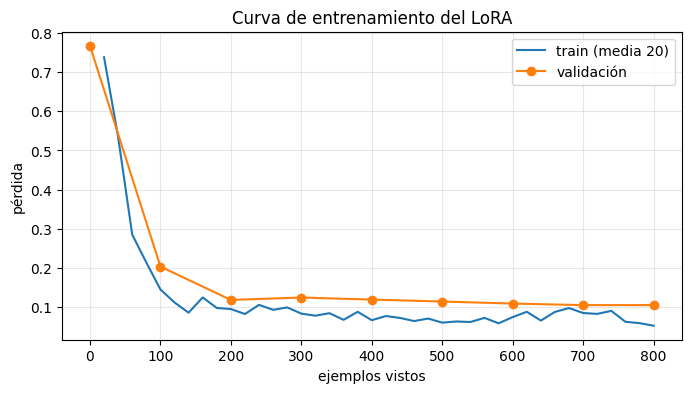

In [ ]:
h = pd.DataFrame(historial)
plt.figure(figsize=(8, 4))
if "train" in h:
    plt.plot(h.dropna(subset=["train"])["ejemplo"], h.dropna(subset=["train"])["train"], label="train (media 20)")
if "val" in h:
    plt.plot(h.dropna(subset=["val"])["ejemplo"], h.dropna(subset=["val"])["val"], "o-", label="validación")
plt.xlabel("ejemplos vistos"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=.3)
plt.title("Curva de entrenamiento del LoRA"); plt.show()

## 8. Evaluación: el mismo modelo en 4 bits, sin LoRA y con LoRA

`modelo.disable_adapter()` apaga el LoRA temporalmente: es exactamente el modelo base en 4 bits. Así la comparación aísla el efecto del entrenamiento.

In [ ]:
def metricas(res):
    y = res["clase"] == "positiva"
    p = res["pred_incidente"].fillna(False).astype(bool)
    vp, fn, fp, vn = int((y & p).sum()), int((y & ~p).sum()), int((~y & p).sum()), int((~y & ~p).sum())
    prec = vp / (vp + fp) if vp + fp else float("nan")
    rec = vp / (vp + fn) if vp + fn else float("nan")
    det = res[y & p]
    tipo_ok = (det["pred_tipo"] == det["tipo_real"].map(tipo_json)).mean() if len(det) else float("nan")
    con_t = det[det["pred_segundo_aprox"].notna()]
    err_t = (con_t["pred_segundo_aprox"] - con_t["t_rel"]).abs()
    return {"VP": vp, "FN": fn, "FP": fp, "VN": vn, "precision": prec, "recall": rec,
            "F1": 2 * prec * rec / (prec + rec) if prec + rec else float("nan"),
            "falsas_alarmas": fp / (fp + vn) if fp + vn else float("nan"),
            "tipo_correcto": tipo_ok, "err_t_mediano_s": err_t.median() if len(err_t) else float("nan"),
            "t_dentro_2s": (err_t <= 2).mean() if len(err_t) else float("nan"),
            "json_ok": (res["formato"] == "ok").mean(), "latencia_s": res["segundos"].median()}


def evaluar(nombre):
    filas = []
    modelo.eval(); modelo.config.use_cache = True
    for i, v in TEST.iterrows():
        try:
            r = juzgar_ventana(v, i)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); r = {"incidente": None, "tipo": "sin_memoria", "formato": "sin_memoria"}
        filas.append({**v.drop(labels=["frames"], errors="ignore").to_dict(),
                      **{(f"pred_{k}" if k in ("incidente", "tipo", "segundo_aprox") else k): x for k, x in r.items()}})
        if (i + 1) % 10 == 0:
            print(f"  {nombre}: {i+1}/{len(TEST)}", flush=True)
    res = pd.DataFrame(filas)
    res.to_csv(os.path.join(DIR_RESULTADOS, f"test_{nombre}_{time.strftime('%Y%m%d_%H%M')}.csv"), index=False)
    return res


with modelo.disable_adapter():
    res_base = evaluar("base_4bit")
res_lora = evaluar("lora")

tabla = pd.DataFrame({"Qwen 4 bits sin LoRA": metricas(res_base), "Qwen 4 bits + LoRA": metricas(res_lora)})
solo_r2a = TEST["origen"] == "R2a"
if solo_r2a.any():
    tabla["LoRA (solo ventanas R2a)"] = pd.Series(metricas(res_lora[solo_r2a.values]))
def _fmt(x):
    if isinstance(x, float) and not np.isnan(x):
        return f"{x:.0%}" if abs(x) <= 1 else f"{x:.1f}"
    return x
print(tabla.apply(lambda col: col.map(_fmt)).to_string())
tabla.to_csv(os.path.join(DIR_RESULTADOS, f"comparacion_{HUELLA}.csv"))

  base_4bit: 10/60
  base_4bit: 20/60
  base_4bit: 30/60
  base_4bit: 40/60
  base_4bit: 50/60
  base_4bit: 60/60
  lora: 10/60
  lora: 20/60
  lora: 30/60
  lora: 40/60
  lora: 50/60
  lora: 60/60
                Qwen 4 bits sin LoRA Qwen 4 bits + LoRA
VP                              30.0               28.0
FN                                0%                2.0
FP                              29.0               28.0
VN                              100%                2.0
precision                        51%                50%
recall                          100%                93%
F1                               67%                65%
falsas_alarmas                   97%                93%
tipo_correcto                    47%                57%
err_t_mediano_s                  1.7                1.5
t_dentro_2s                      53%                68%
json_ok                         100%               100%
latencia_s                       8.6               10.6


In [ ]:
print("Matriz de confusión del tipo (LoRA, positivas detectadas):")
det = res_lora[(res_lora["clase"] == "positiva") & res_lora["pred_incidente"].fillna(False).astype(bool)].copy()
det["tipo_esperado"] = det["tipo_real"].map(tipo_json)
display(pd.crosstab(det["tipo_esperado"], det["pred_tipo"], margins=True))

print("\nFalsas alarmas que quedan (LoRA):")
display(res_lora[(res_lora["clase"] == "negativa") & res_lora["pred_incidente"].fillna(False).astype(bool)]
        [["video", "inicio", "fin", "pred_tipo", "descripcion"]])
print("\nChoques perdidos (LoRA):")
display(res_lora[(res_lora["clase"] == "positiva") & ~res_lora["pred_incidente"].fillna(False).astype(bool)]
        [["video", "tipo_real", "t_rel", "descripcion"]])

Matriz de confusión del tipo (LoRA, positivas detectadas):


pred_tipo,en_t,roce_lateral,un_vehiculo,All
tipo_esperado,,,,
alcance,0,1,3,4
en_t,8,2,3,13
frontal,1,0,1,2
roce_lateral,0,1,1,2
un_vehiculo,0,0,7,7
All,9,4,15,28



Falsas alarmas que quedan (LoRA):


,video,inicio,fin,pred_tipo,descripcion
1,QbTAfMWdSN0_00,0.000000,5.583000,en_t,Choque en T en un cruce con semáforo.
3,sKJdbm04q6U_00,0.000000,7.333000,un_vehiculo,Choque de un solo vehículo en una autopista de...
5,Czp_f_DrRB8_00,0.000000,7.916666,un_vehiculo,Choque de un solo vehículo en una autopista.
7,aRQeSqO9Ri4_00,0.000000,4.792000,en_t,Choque en T en un cruce con semáforo de noche.
9,BiAj8Q5I710_00,0.105112,8.105112,un_vehiculo,Choque de un solo vehículo en una autopista de...
11,ZvegJ-6a3ow_00,0.000000,5.964000,un_vehiculo,Choque de un solo vehículo en la vía.
13,ltBaGt6A30I_00,0.000000,6.175833,en_t,Choque en T en un cruce con semáforo.
15,a5AAO2Kcnhg_00,5.844160,13.844160,un_vehiculo,Choque de un solo vehículo en una autopista de...
17,NdXcu0X1nH8_00,0.000000,6.292000,en_t,Choque en T en un cruce con semáforo.
19,1BIZOZtxRpY_00,0.000000,6.625000,un_vehiculo,Choque de un solo vehículo en una autopista de...



Choques perdidos (LoRA):


,video,tipo_real,t_rel,descripcion
36,q0ReAwAoB6c_00,t-bone,5.68789,"Tráfico normal en una autopista, sin choques."
52,WA6hL9bRnNs_00,single,8.00000,"Tráfico normal en una autopista, sin choques."


## Cómo leer los resultados

- **Lo principal: falsas alarmas.** La base estaba en 100 %. Si el LoRA las baja sin hundir el recall, la cascada funciona: el supervisor filtra lo que el detector manda por error.
- **Tipo:** la base daba ~20 % (azar). Cualquier cosa claramente arriba de 20 % es aprendizaje real.
- **Tiempo:** error mediano en segundos y % dentro de ±2 s.
- **Curva de pérdida:** si la validación sube mientras train baja, hay sobreajuste. Baja `MAX_EJEMPLOS`/`EPOCAS` o sube `lora_dropout`.
- **Limitaciones para el reporte:** las descripciones son de plantilla; 1 época; test de ~70 ventanas (los porcentajes tienen margen de error de ±10 puntos o más); los sintéticos ayudan con los tipos, pero el dominio real es CCTV de internet, no del C5 de Guadalajara.